# Build the dataset from all charts

This notebook cuts the tiles of all charts, writes the labels, and splits them into train, validation, and test.

**Map area:** `configs/chart_areas.json` has the outline of the main map of each chart, as longitude and latitude points.
The outlines come from the pirep project (AGPL-3.0). A tile is kept only if its four corners are inside the outline.

**Order of work:**
1. Put `chart_areas.json` in the `configs` folder.
2. Run Cells 1 to 5. In Cell 5, the red line must follow the edges of the main map.
3. Run Cells 6 to 9. Then look at the check images in `data/processed/all/checks`.
4. If a check image shows tiles on an inset, add an exclusion box for that chart in Cell 1. Delete `data/processed/all` and run Cells 6 to 9 again.
5. Run Cell 10 some times to check random samples.

## Cell 1: Imports and settings

In [1]:
import os
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.path import Path
import rasterio
from rasterio.warp import transform
from rasterio.transform import rowcol, xy
from rasterio.windows import Window
from PIL import Image

CHART_DIR = "../data/raw/charts"
APT_CSV = "../data/raw/29_Oct_2026_APT_CSV/APT_BASE.csv"
NAV_CSV = "../data/raw/29_Oct_2026_NAV_CSV/NAV_BASE.csv"
TABLE = "../configs/charts.csv"
AREAS = "../configs/chart_areas.json"
OUT_DIR = "../data/processed/all"

TILE = 1024     # Tile size in pixels.
STRIDE = 896    # Distance between tile starts. 1024 - 896 = 128 pixels of overlap.
SCALE = 10      # The check images are 1/10 of the real size.

QUESTION = "List all airports and navaids in this image with their pixel positions."

# Areas to skip, for example insets. Real pixel values: (row_min, row_max, col_min, col_max).
# Los Angeles: the Los Angeles Basin inset at the bottom left.
EXCLUDE_BOXES = {
    "Los Angeles": [(8100, 12400, 0, 4700)],
}

## Cell 2: Load the chart table and the map outlines

In [2]:
charts = pd.read_csv(TABLE)[["chart", "tif_file", "split"]]

# One outline for each chart. A Path can test if points are inside the outline.
with open(AREAS) as f:
    outlines = json.load(f)["charts"]
PATHS = {name: Path(np.array(points)) for name, points in outlines.items()}

# Each chart in the table must have an outline.
missing = [c for c in charts["chart"] if c not in PATHS]
print("Charts:", len(charts))
print("Charts with no outline:", missing)

Charts: 34
Charts with no outline: []


## Cell 3: Load the airports and navaids

In [3]:
apt = pd.read_csv(APT_CSV, low_memory=False)
nav = pd.read_csv(NAV_CSV, low_memory=False)

# Keep only airports. Remove heliports, seaplane bases, and other types.
apt = apt[apt["SITE_TYPE_CODE"] == "A"]

# One table with the same columns for airports and navaids.
objs_all = pd.concat([
    pd.DataFrame({"type": "airport", "id": apt["ARPT_ID"], "lat": apt["LAT_DECIMAL"], "lon": apt["LONG_DECIMAL"]}),
    pd.DataFrame({"type": "navaid", "id": nav["NAV_ID"], "lat": nav["LAT_DECIMAL"], "lon": nav["LONG_DECIMAL"]}),
], ignore_index=True)

print(objs_all["type"].value_counts())

type
airport    13005
navaid      1608
Name: count, dtype: int64


## Cell 4: Helper functions

In [4]:
def make_lut(src):
    # The chart has 1 band with a color table. This lookup table converts each index to an RGB color.
    lut = np.zeros((256, 3), dtype=np.uint8)
    for index, color in src.colormap(1).items():
        lut[index] = color[:3]
    return lut


def pixels_to_lonlat(src, rows, cols):
    # Pixel row and column -> chart projection -> longitude and latitude.
    xs, ys = xy(src.transform, rows, cols)
    lons, lats = transform(src.crs, "EPSG:4326", xs, ys)
    return np.array(lons), np.array(lats)


def lonlat_to_pixels(src, lons, lats):
    # Longitude and latitude -> chart projection -> pixel row and column.
    xs, ys = transform("EPSG:4326", src.crs, list(lons), list(lats))
    rows, cols = rowcol(src.transform, xs, ys)
    return np.array(rows), np.array(cols)


def inside_map(chart, lons, lats):
    # True for each point inside the main map outline of the chart.
    return PATHS[chart].contains_points(np.column_stack([lons, lats]))


def overlaps(r, c, box):
    # True if the tile at (r, c) touches the exclusion box.
    r0, r1, c0, c1 = box
    return r < r1 and r + TILE > r0 and c < c1 and c + TILE > c0

## Cell 5: Check the outline on one chart

The red line is the main map outline. It must follow the edges of the main map.
Change the chart name to check other charts.

/var/folders/hv/ssw7w9251n33ldwz20jqx8qw0000gn/T/ipykernel_47619/3839019630.py:5: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  small = src.read(1, out_shape=(src.height // SCALE, src.width // SCALE))


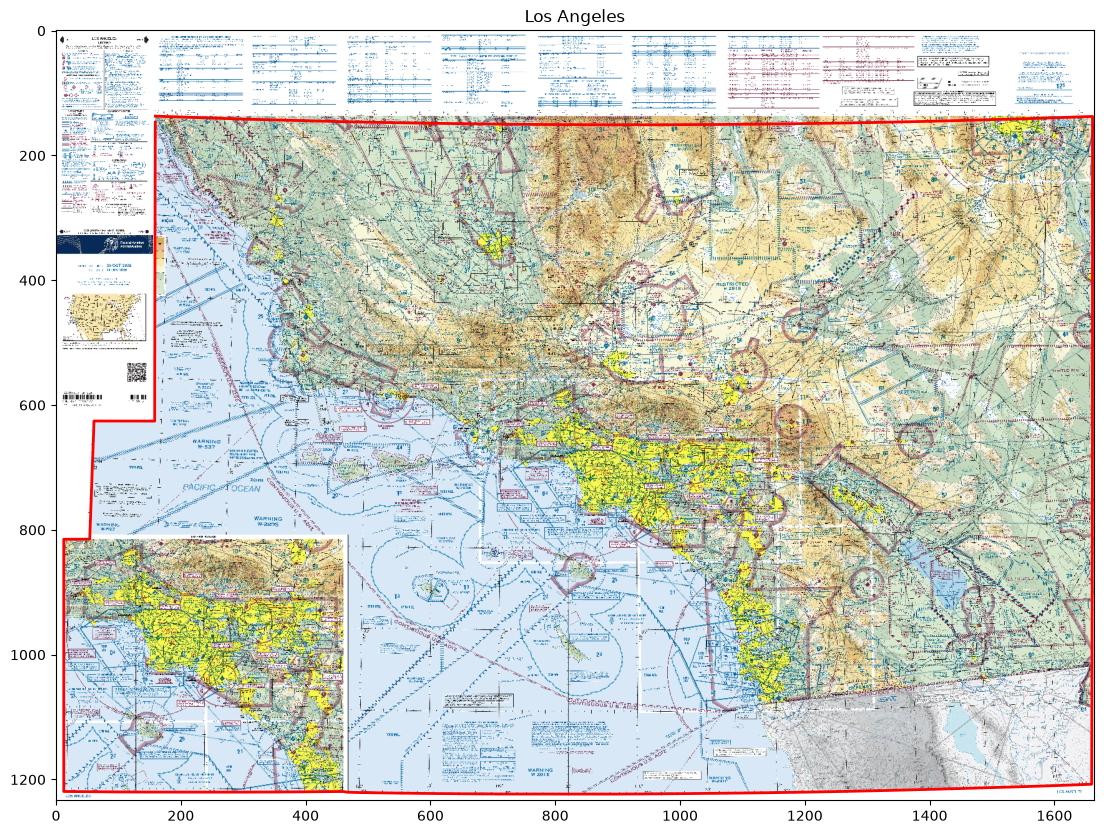

In [5]:
def show_outline(chart):
    tif_file = charts.loc[charts["chart"] == chart, "tif_file"].iloc[0]
    with rasterio.open(os.path.join(CHART_DIR, tif_file)) as src:
        lut = make_lut(src)
        small = src.read(1, out_shape=(src.height // SCALE, src.width // SCALE))

        # Add points along each edge of the outline, because the edges are curved on the image.
        pts = np.array(outlines[chart])
        dense = np.concatenate([np.linspace(p0, p1, 50, endpoint=False) for p0, p1 in zip(pts[:-1], pts[1:])])
        rows, cols = lonlat_to_pixels(src, dense[:, 0], dense[:, 1])

    plt.figure(figsize=(16, 10))
    plt.imshow(lut[small])
    plt.plot(cols / SCALE, rows / SCALE, "r-", linewidth=2)
    plt.title(chart)
    plt.show()

show_outline("Los Angeles")

## Cell 6: Process one chart

In [6]:
def process_chart(b):
    tile_dir = os.path.join(OUT_DIR, "tiles", b.chart)
    os.makedirs(tile_dir, exist_ok=True)
    boxes = EXCLUDE_BOXES.get(b.chart, [])
    records = []

    # Keep only the objects inside the main map outline of this chart.
    o = objs_all[inside_map(b.chart, objs_all["lon"].values, objs_all["lat"].values)].copy()

    with rasterio.open(os.path.join(CHART_DIR, b.tif_file)) as src:
        lut = make_lut(src)
        o["px_row"], o["px_col"] = lonlat_to_pixels(src, o["lon"], o["lat"])

        for r in range(0, src.height - TILE + 1, STRIDE):
            for c in range(0, src.width - TILE + 1, STRIDE):

                # Skip the tile if a corner is outside the main map (legend, border).
                lons, lats = pixels_to_lonlat(src, [r, r, r + TILE - 1, r + TILE - 1], [c, c + TILE - 1, c, c + TILE - 1])
                if not inside_map(b.chart, lons, lats).all():
                    continue

                # Skip the tile if it touches an exclusion box (inset).
                if any(overlaps(r, c, box) for box in boxes):
                    continue

                # Skip the tile if it has no objects.
                ins = o[o["px_row"].between(r, r + TILE - 1) & o["px_col"].between(c, c + TILE - 1)]
                if len(ins) == 0:
                    continue

                # Read the tile, convert it to RGB, and save it.
                band = src.read(1, window=Window(c, r, TILE, TILE))
                file_name = f"r{r}_c{c}.png"
                Image.fromarray(lut[band]).save(os.path.join(tile_dir, file_name))

                # Sort the objects from top to bottom, then left to right.
                # Change the positions so that they start from the top-left corner of the tile.
                ins = ins.sort_values(["px_row", "px_col"])
                answer = [
                    {"type": t, "id": i, "x": int(pc - c), "y": int(pr - r)}
                    for t, i, pr, pc in zip(ins["type"], ins["id"], ins["px_row"], ins["px_col"])
                ]

                records.append({
                    "chart": b.chart,
                    "image": f"tiles/{b.chart}/{file_name}",
                    "row": r,
                    "col": c,
                    "question": QUESTION,
                    "answer": json.dumps(answer),
                })

    return records

## Cell 7: Save a check image for one chart

In [7]:
def save_check_image(b, records):
    # Draw each kept tile as a red square on the small chart image.
    check_dir = os.path.join(OUT_DIR, "checks")
    os.makedirs(check_dir, exist_ok=True)

    with rasterio.open(os.path.join(CHART_DIR, b.tif_file)) as src:
        lut = make_lut(src)
        small = src.read(1, out_shape=(src.height // SCALE, src.width // SCALE))

    plt.figure(figsize=(16, 10))
    plt.imshow(lut[small])
    for rec in records:
        plt.gca().add_patch(plt.Rectangle((rec["col"] / SCALE, rec["row"] / SCALE), TILE / SCALE, TILE / SCALE, fill=False, edgecolor="red", linewidth=1))
    plt.title(f"{b.chart}: {len(records)} tiles")
    plt.savefig(os.path.join(check_dir, f"{b.chart}.png"), dpi=80)
    plt.close()

## Cell 8: Process all charts

This cell can take some minutes.

In [8]:
all_records = []
for b in charts.itertuples():
    records = process_chart(b)
    save_check_image(b, records)
    all_records += records
    print(f"{b.chart}: {len(records)} tiles")

print("Total tiles:", len(all_records))

/var/folders/hv/ssw7w9251n33ldwz20jqx8qw0000gn/T/ipykernel_47619/922737310.py:32: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  band = src.read(1, window=Window(c, r, TILE, TILE))
/var/folders/hv/ssw7w9251n33ldwz20jqx8qw0000gn/T/ipykernel_47619/694530018.py:8: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  small = src.read(1, out_shape=(src.height // SCALE, src.width // SCALE))


Albuquerque: 107 tiles
Atlanta: 168 tiles
Billings: 112 tiles
Brownsville: 31 tiles
Charlotte: 110 tiles
Cheyenne: 115 tiles
Chicago: 168 tiles
Cincinnati: 153 tiles
Dallas-Ft Worth: 163 tiles
Denver: 113 tiles
Detroit: 143 tiles
El Paso: 42 tiles
Great Falls: 151 tiles
Green Bay: 114 tiles
Houston: 117 tiles
Jacksonville: 85 tiles
Kansas City: 165 tiles
Klamath Falls: 127 tiles
Las Vegas: 90 tiles
Los Angeles: 98 tiles
Memphis: 164 tiles
Miami: 61 tiles
New Orleans: 78 tiles
New York: 142 tiles
Omaha: 177 tiles
Phoenix: 115 tiles
Salt Lake City: 118 tiles
San Antonio: 133 tiles
San Francisco: 111 tiles
Seattle: 161 tiles
St Louis: 161 tiles
Twin Cities: 172 tiles
Washington: 94 tiles
Wichita: 144 tiles
Total tiles: 4203


## Cell 9: Split by chart and save the labels

In [9]:
# Each chart is fully in one split. Thus, the model never sees the test areas in training.
split_of = dict(zip(charts["chart"], charts["split"]))

for split in ["train", "val", "test"]:
    rows = [rec for rec in all_records if split_of[rec["chart"]] == split]
    with open(os.path.join(OUT_DIR, f"{split}.jsonl"), "w") as f:
        for rec in rows:
            f.write(json.dumps(rec) + "\n")
    print(f"{split}: {len(rows)} tiles")

train: 3475 tiles
val: 393 tiles
test: 335 tiles


## Cell 10: Check a random sample

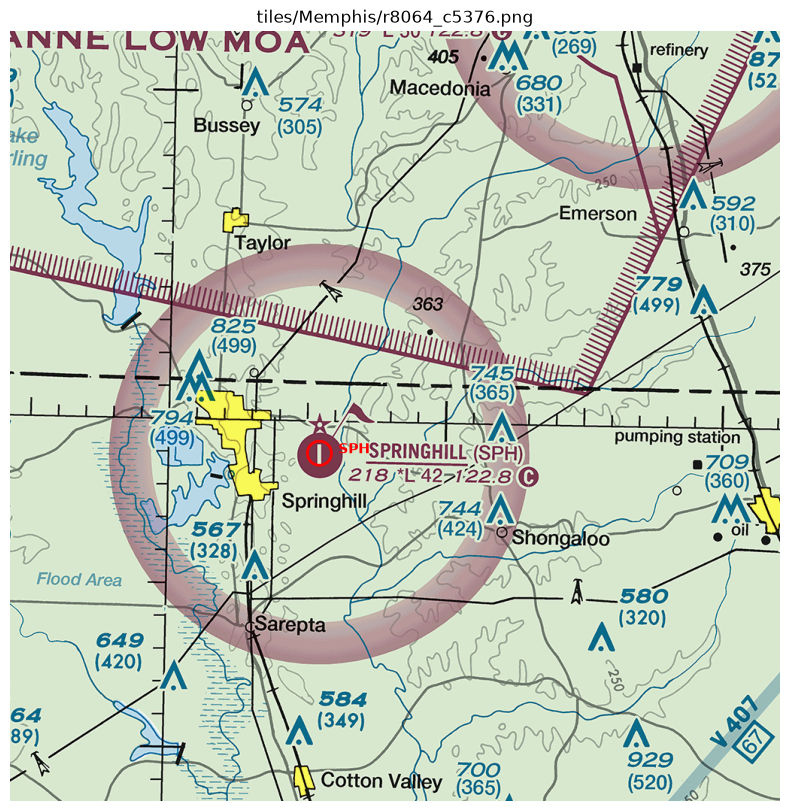

[{"type": "airport", "id": "SPH", "x": 411, "y": 561}]


In [10]:
# Each run shows a different random sample. Each mark must be on the correct symbol.
sample = random.choice(all_records)
img = Image.open(os.path.join(OUT_DIR, sample["image"]))
objects = json.loads(sample["answer"])

plt.figure(figsize=(10, 10))
plt.imshow(img)
for o in objects:
    color = "red" if o["type"] == "airport" else "blue"
    plt.scatter(o["x"], o["y"], s=300, facecolors="none", edgecolors=color, linewidths=2)
    plt.text(o["x"] + 25, o["y"], o["id"], color=color, fontsize=10, weight="bold")
plt.title(sample["image"])
plt.axis("off")
plt.show()

print(sample["answer"])